In [1]:
import pandas as pd
df = pd.read_csv("../data/raw/AAU_temperature_and_power_use.csv")
print(df.columns.tolist())

['Time [Date/Time]', 'Power Ch 1 (W)', 'Power Ch 2 (W)', 'Power Ch 3 (W)', 'Temperature mod 1 ch 1', 'Temperature mod 1 ch 2', 'Temperature mod 1 ch 3', 'Temperature mod 1 ch 4', 'Temperature mod 1 ch 5', 'Temperature mod 1 ch 6', 'Temperature mod 1 ch 7', 'Temperature mod 1 ch 8', 'Temperature mod 2 ch 1', 'Temperature mod 2 ch 2', 'Temperature mod 2 ch 3', 'Temperature mod 2 ch 4', 'Temperature mod 2 ch 5', 'Temperature mod 2 ch 6', 'Temperature mod 2 ch 7', 'Temperature mod 2 ch 8', 'Temperature mod 3 ch 1', 'Temperature mod 3 ch 2', 'Temperature mod 3 ch 3', 'Temperature mod 3 ch 4', 'Temperature mod 3 ch 5', 'Temperature mod 3 ch 6', 'Temperature mod 3 ch 7', 'Temperature mod 3 ch 8', 'Temperature mod 4 ch 1', 'Temperature mod 4 ch 2', 'Temperature mod 4 ch 3', 'Temperature mod 4 ch 4', 'Temperature mod 4 ch 5', 'Temperature mod 4 ch 6', 'Temperature mod 4 ch 7', 'Temperature mod 4 ch 8', 'Temperature mod 5 ch 1', 'Temperature mod 5 ch 2', 'Temperature mod 5 ch 3', 'Temperature mo

In [2]:
import pandas as pd
df = pd.read_csv("../data/raw/Alibaba_Cluster_Trace.csv")
print(df.columns.tolist())

['avg_cpu', 'avg_mem', 'avg_assigned_mem', 'avg_cycles_per_instruction']


In [3]:
import pandas as pd
import numpy as np

# --- AAU: temperature + power ---
aau = pd.read_csv("../data/raw/AAU_temperature_and_power_use.csv")

print("AAU shape:", aau.shape)

# Time column has a space and brackets — must match exactly
aau['Time [Date/Time]'] = pd.to_datetime(
    aau['Time [Date/Time]'], errors='coerce'
)

print("AAU time range:",
      aau['Time [Date/Time]'].min(), "→",
      aau['Time [Date/Time]'].max())

# Most common gap between rows = nominal sampling interval
gaps = aau['Time [Date/Time]'].diff().dropna()
print("AAU most common time step:", gaps.mode().iloc[0])

# How many rows per temperature channel — should all be equal
temp_cols = [c for c in aau.columns if c.startswith("Temperature")]
print("AAU temperature columns:", len(temp_cols))
print("AAU non-null per temp column (first 5):")
print(aau[temp_cols[:5]].notna().sum())

# Power columns
power_cols = [c for c in aau.columns if c.startswith("Power")]
print("AAU power columns:", power_cols)
print(aau[power_cols].describe())

AAU shape: (1371363, 52)
AAU time range: 2024-09-16 16:58:30 → 2024-10-02 13:53:02
AAU most common time step: 0 days 00:00:01
AAU temperature columns: 48
AAU non-null per temp column (first 5):
Temperature mod 1 ch 1    1371363
Temperature mod 1 ch 2    1371363
Temperature mod 1 ch 3    1371363
Temperature mod 1 ch 4    1371363
Temperature mod 1 ch 5    1371363
dtype: int64
AAU power columns: ['Power Ch 1 (W)', 'Power Ch 2 (W)', 'Power Ch 3 (W)']
       Power Ch 1 (W)  Power Ch 2 (W)  Power Ch 3 (W)
count    1.371363e+06    1.371363e+06    1.371363e+06
mean     1.290452e+03    6.509688e+02    6.590363e+02
std      7.282411e+01    1.479397e+01    3.600058e+02
min      1.130800e+03    6.377000e+02    3.930000e+02
25%      1.237700e+03    6.403000e+02    3.948000e+02
50%      1.285600e+03    6.424000e+02    3.961000e+02
75%      1.336200e+03    6.549000e+02    1.060900e+03
max      1.717000e+03    8.674000e+02    1.332800e+03


In [5]:
# --- Alibaba: workload (current header only) ---
ali = pd.read_csv("../data/raw/Alibaba_Cluster_Trace.csv")

print("Alibaba shape:", ali.shape)
print("Alibaba columns:", ali.columns.tolist())

# Check for a time column under any name
for candidate in ['time', 'timestamp', 'Time', 'ts', 'date']:
    if candidate in ali.columns:
        print(f"Found time column: {candidate}")
        break
else:
    print("NO TIME COLUMN — cannot build a time series from this file")

print(ali.head())
print(ali.describe())

Alibaba shape: (8064, 4)
Alibaba columns: ['avg_cpu', 'avg_mem', 'avg_assigned_mem', 'avg_cycles_per_instruction']
NO TIME COLUMN — cannot build a time series from this file
    avg_cpu   avg_mem  avg_assigned_mem  avg_cycles_per_instruction
0  0.441616  0.332384          0.624016                  148.617607
1  0.433129  0.326703          0.615745                  148.206223
2  0.411363  0.323445          0.607363                  146.590244
3  0.408045  0.327051          0.609530                  147.094662
4  0.416812  0.333668          0.613534                  149.082095
           avg_cpu      avg_mem  avg_assigned_mem  avg_cycles_per_instruction
count  8064.000000  8064.000000       8064.000000                 8064.000000
mean      0.472823     0.327155          0.597463                  166.127190
std       0.039913     0.022817          0.037010                    9.533895
min       0.320287     0.244980          0.495377                  119.719080
25%       0.449647     0.316

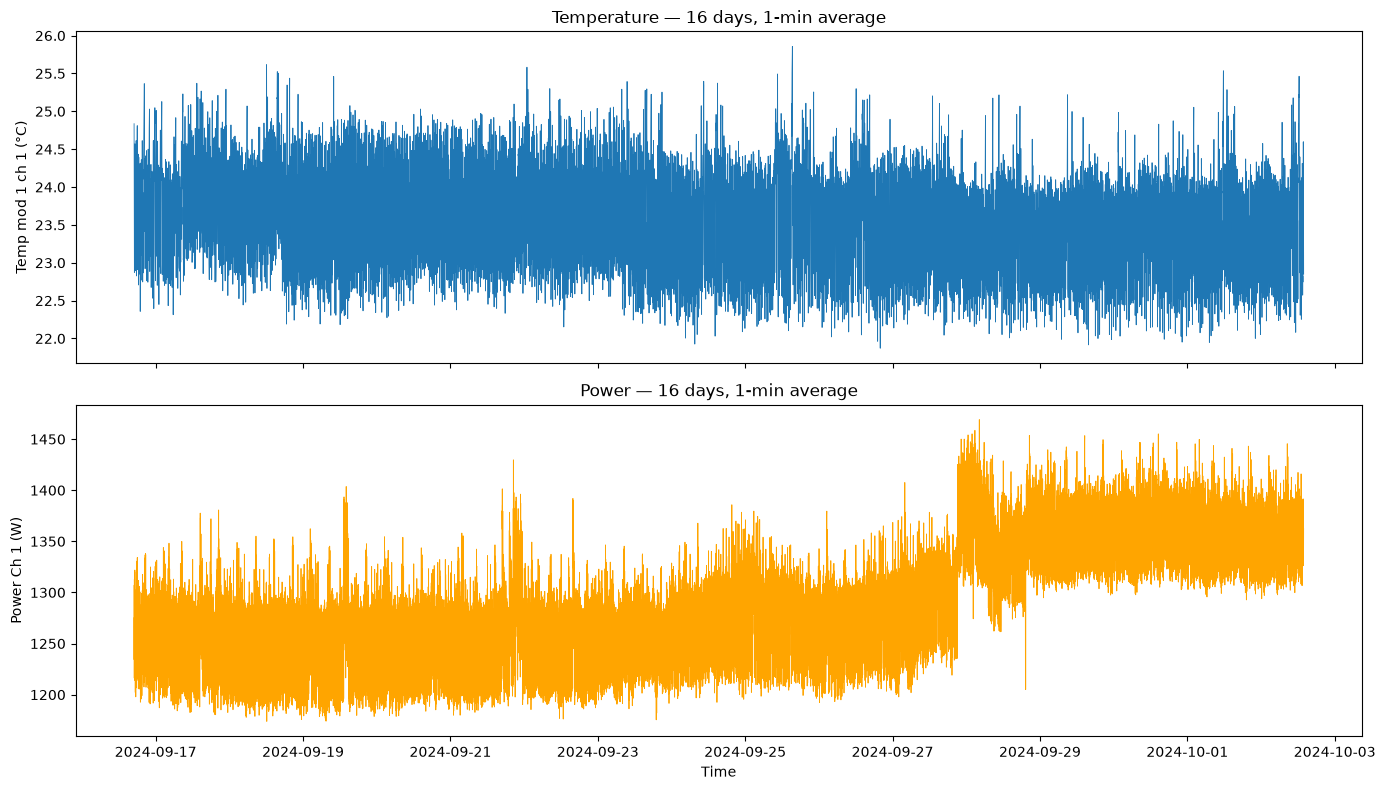

In [6]:
import matplotlib.pyplot as plt

# Downsample to 1 minute for plotting only (1.37M rows is too many to plot)
aau_plot = aau.set_index('Time [Date/Time]').resample('1min').mean().reset_index()

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(aau_plot['Time [Date/Time]'],
             aau_plot['Temperature mod 1 ch 1'], linewidth=0.6)
axes[0].set_ylabel('Temp mod 1 ch 1 (°C)')
axes[0].set_title('Temperature — 16 days, 1-min average')

axes[1].plot(aau_plot['Time [Date/Time]'],
             aau_plot['Power Ch 1 (W)'], linewidth=0.6, color='orange')
axes[1].set_ylabel('Power Ch 1 (W)')
axes[1].set_xlabel('Time')
axes[1].set_title('Power — 16 days, 1-min average')

plt.tight_layout()
plt.savefig('../reports/figures/01_timeseries_overview.png', dpi=150)
plt.show()

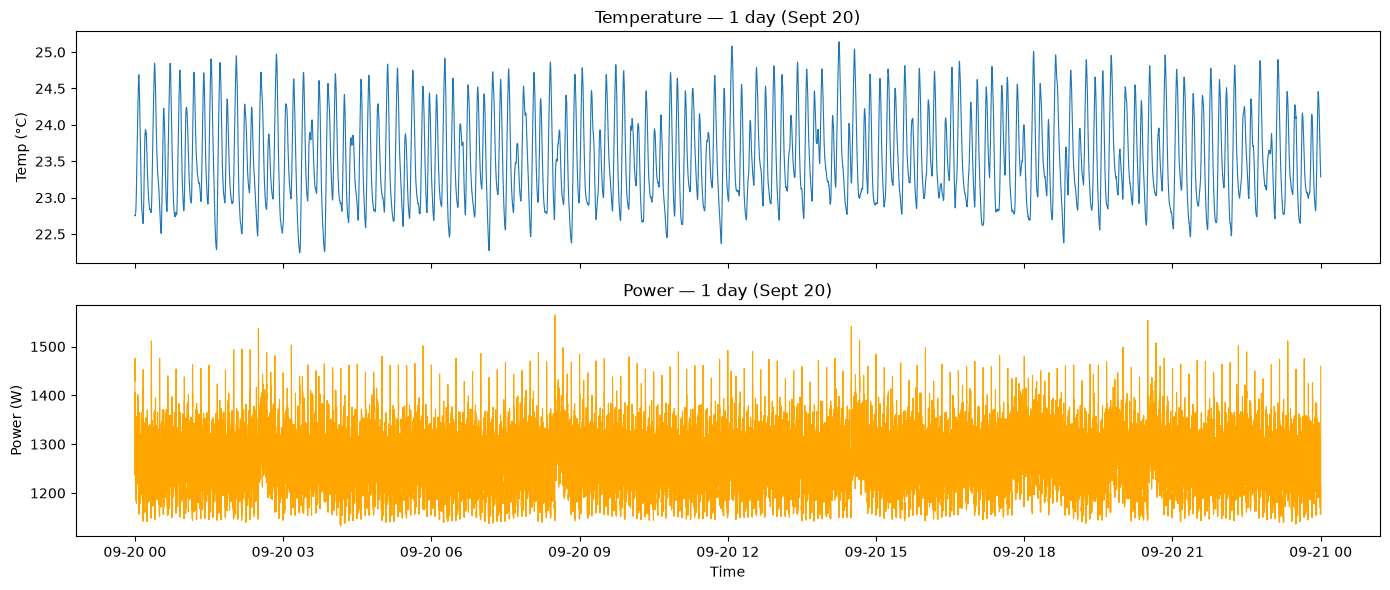

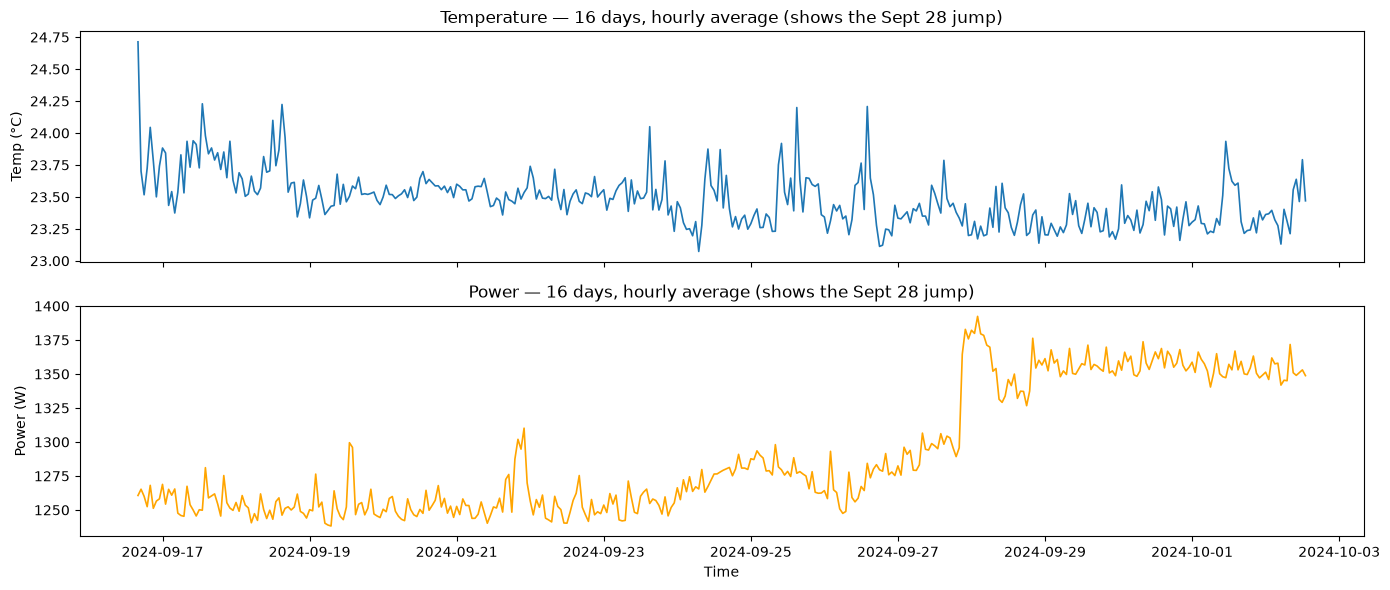

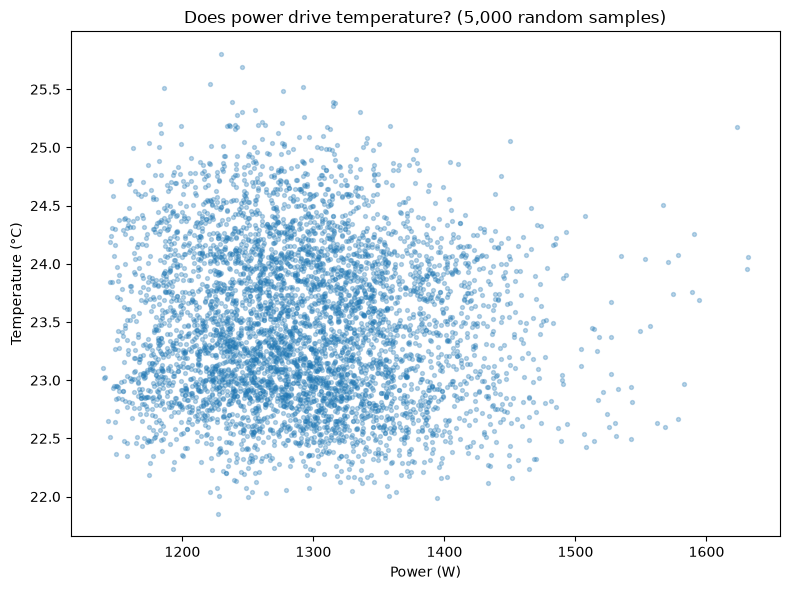

In [7]:
import matplotlib.pyplot as plt
import pandas as pd

# ---- Plot 1: One full day (Sept 20) at 1-minute resolution ----
one_day = aau[
    (aau['Time [Date/Time]'] >= '2024-09-20') &
    (aau['Time [Date/Time]'] <  '2024-09-21')
]

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

axes[0].plot(one_day['Time [Date/Time]'],
             one_day['Temperature mod 1 ch 1'], linewidth=0.8)
axes[0].set_ylabel('Temp (°C)')
axes[0].set_title('Temperature — 1 day (Sept 20)')

axes[1].plot(one_day['Time [Date/Time]'],
             one_day['Power Ch 1 (W)'], linewidth=0.8, color='orange')
axes[1].set_ylabel('Power (W)')
axes[1].set_xlabel('Time')
axes[1].set_title('Power — 1 day (Sept 20)')

plt.tight_layout()
plt.savefig('../reports/figures/01_one_day_view.png', dpi=150)
plt.show()


# ---- Plot 2: Hourly averages over 16 days ----
hourly = aau.set_index('Time [Date/Time]').resample('1h').mean().reset_index()

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

axes[0].plot(hourly['Time [Date/Time]'],
             hourly['Temperature mod 1 ch 1'], linewidth=1.2)
axes[0].set_ylabel('Temp (°C)')
axes[0].set_title('Temperature — 16 days, hourly average (shows the Sept 28 jump)')

axes[1].plot(hourly['Time [Date/Time]'],
             hourly['Power Ch 1 (W)'], linewidth=1.2, color='orange')
axes[1].set_ylabel('Power (W)')
axes[1].set_xlabel('Time')
axes[1].set_title('Power — 16 days, hourly average (shows the Sept 28 jump)')

plt.tight_layout()
plt.savefig('../reports/figures/02_hourly_overview.png', dpi=150)
plt.show()


# ---- Plot 3: Power vs Temperature relationship ----
sample = aau.sample(5000, random_state=42)  # random 5000 rows for scatter

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(sample['Power Ch 1 (W)'],
           sample['Temperature mod 1 ch 1'],
           alpha=0.3, s=8)
ax.set_xlabel('Power (W)')
ax.set_ylabel('Temperature (°C)')
ax.set_title('Does power drive temperature? (5,000 random samples)')
plt.tight_layout()
plt.savefig('../reports/figures/03_power_vs_temp.png', dpi=150)
plt.show()